In [1]:
theta = [50000, 75000, 0.4116, 111900, 9905, 30000]
theta_n = [100000, 100000, 1, 100000, 100, 10000]
theta_mins = [10000, 0, 0.1, 50000, 10, 10000]
theta_maxs = [1000000, 200000, 10, 200000, 10000, 200000]

In [2]:
system = {
    'tvi': {  # Time-variant input variables (models input: tvi), each key is a symbol nad key in tvi as well
        'u1': {  # Temperature (K)
            'stps': 6,  # Number of switching times in CVPs (vector parametrisation resolution in time dimension):
            # Must be a positive integer > 1. swps-1 is the number of steps
            'const': 'rel',  # Constraint type: relative state of signal levels in CVPs
            # 'rel' (relative) ensures relaxation, 'dec' (decreasing) ensures decreasing signal levels, 'inc' (increasing) ensures increasing signal levels
            'max': 306.15,  # Maximum allowable signal level, des_opt space upper bound
            'min': 296.15,  # Minimum allowable signal level, des_opt space lower bound
            'cvp': 'LPF',  # Design CVP method (CPF - constant profile, LPF - linear profile)
            'offl': 0.05,  # minimum allowed perturbation of signal (ratio)
            'offt': 0.5  # minimum allowed perturbation of time (ratio)
        },
    },
    'tvo': {  # Time-variant output variables (responses, measured or unmeasured)
        'y1': {  # response variable, here carbonation efficiency
            'init': 0,  # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,  # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,  # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
        'y2': {  # response variable, here carbonation efficiency
            'init': 0,  # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,  # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,  # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
        'y3': {  # response variable, here carbonation efficiency
            'init': 0,
            # Initial value for the response variable, it can be a value, or 'variable' for case it is a des_opt decision (time-invariant input variable)
            'meas': True,
            # Flag indicating if this variable is directly measurable, if False, it is a virtual output
            'sp': 10,  # the amound of samples per each round (run)
            'unc': 0.005,
            # amount of noise (standard deviation) in the measurement, in case of insilico, this is used for simulating a normal distribution of noise to measurement (only measurement)
            'offt': 0.3,  # minimum allowed perturbation of sampling times (ratio)
            'samp_s': 1,  # Matching criterion for models prediction and data alignment
            'samp_f': [0, 16],  # fixed sampling times
        },
    },
    'tii': {  # Time-invariant input variables (tii)
        'y10': {  # 1st symbolic time-invariant control, Density of solid reactant (kg/m³)
            'max': 1,  # Maximum allowable signal level, des_opt space upper bound
            'min': 0.3  # Minimum allowable signal level, des_opt space upper bound
        },
        'y20': {  # 1st symbolic time-invariant control, Density of solid reactant (kg/m³)
            'max': 1,  # Maximum allowable signal level, des_opt space upper bound
            'min': 0.19  # Minimum allowable signal level, des_opt space upper bound
        },
    },
    'tio': {  # Time-invariant output variables (empty here, could hold steady state responses that hold no dependency)
    },
    't_s': [0, 16],  # Time span  (600 s to 10,800 s), duration of numerical perturbations (the rest is precluded from des_opt)
    't_r': 0.02,  # Time resolution (10 s), minimum time steps for the simulation/des_opt/controls
    't_d': 0.3
}

models = { # Settings related to the rival models and their parameters
    'can_m': ['M'],  # Active solvers (rival models) to be used in the experiment
    'krt': {'M': 'pys'},  # Kernel type for each model, 'pys' for python standalone scripts, 'pym' for middoe.krnl_models, 'gpr' for gPAS models
    # type of the model interface, 'pym' for middoe.krnl_models, 'gpr' for gPAS models, function name for globally defined functions, 'pys' for python standalone scripts
    'creds': {'M': '@@TTmnoa698'},
    # credentials for gPAS models, if not needed, leave empty
    'src': {'M': 'C:/Users/Tadmin/PycharmProjects/middoe/tests/paper3/2D+2D-LC/model.py'},
    # for now for gPAS readable files, or python standalone scripts

    'theta': { # Theta parameters for each models
        'M': theta_n
    },
    't_u': { # Maximum bounds for theta parameters (based on normalized to'f20': theta20mins, 1)
        'M': theta_maxs
    },
    't_l': { # Minimum bounds for theta parameters (based on normalized to 1)
        'M': theta_mins
    },
    'mutation': { # Mutation settings for each model
        'M': [False, False, True, True, True, True]  # Mutation for each parameter in the model
    }
}

In [3]:
insilicos = { # Settings for the insilico data generation
    'tr_m': 'M', # selected true models (with nominal values)
    'theta': theta,
    'errt': 'abs',  # error type, 'rel' for relative error, 'abs' for absolute error
    'prels': { # classic des_opt settings, sheet name is the round run name, each sheet contains the data for the round, iso space.
    }
}

In [4]:
des_opt = { # Design settings for the experiment
    'eps': 1e-5, #perturbation size of parameters in SA FDM method (in a normalized to 1 space)
    'md_ob': 'BFF',     # MD optimality criterion, 'HR': Hunter and Reiner, 'BFF': Buzzi-Ferraris and Forzatti
    'pp_ob': 'D',  # PP optimality criterion, 'D', 'A', 'E', 'ME'
    'plt': True,  # Plot the results
    'meth': 'PS',
    # optimisation method, 'G': Global Differential Evolution, 'L': Local Pattern Search, 'GL': Global Differential Evolution refined with Local Pattern Search
    'conv_rep': True,        # report optimisation convergence metrics
    'priors': False,    # prior information included

    'itr': {
        'pps': 50, # population size
        'maxmd': 5, # maximum number of MD runs
        'tolmd': 1, # tolerance for MD optimization
        'maxpp':50 ,# maximum number of PP runs
        'tolpp': 1, # tolerance for PP optimization
    }
}

In [5]:
iden_opt = { # Settings for the parameter estimation process
    'meth': 'TC',  #'SLSQP', 'SQP', 'DE', 'NM', 'BFGS', 'LBFGSB'
    'ms': True, # multi starting   # True or False
    'maxit': 500,
    'tol': 0.1,
    'sens_m': 'central', # 'central',  and 'forward' for FDM precision
    'var-cov': 'M', # 'H' for based on hessidan, and 'M' for based on fisher
    'nboot':50,
    'init': None,   # use 'rand' to have random starting point and use None to start from theta_parameters nominal values (to be avoided in insilico studies)
    'eps': 1e-5,  # perturbation size of parameters in SA FDM method (in a normalized to 1 space)e-
    #usually 1e-3, or None to perform a mesh independency test, and auto adjustment
    'ob': 'WLS',  #loss function, 'LS': least squares, 'MLE': maximum likelihood, 'Chi': chi-square, 'WLS': weighted least squares
    'c_plt': False, # plot the confidence volumes
    'f_plt': True, # plot the fitting results
    'plt_s': True, # show plots while saving
    'model_update': True,      # model update to EA suggestion
    'log': False # log the results
}

In [6]:
from middoe.des_pp import mbdoe_pp
designs = mbdoe_pp(des_opt, system, models, round=1, num_parallel_runs=16)

In [7]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=1, swps=designs['swps'])

[✓] In-silico data saved to: C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\data.xlsx
[INFO] Model used         : M
[INFO] Design case        : MBDoE
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.005
   - y2         | measurable      | std.dev = 0.005
   - y3         | measurable      | std.dev = 0.005


(WindowsPath('C:/Users/Tadmin/PycharmProjects/middoe/tests/paper3/2D+2D-LC/data.xlsx'),
      MES_X:y1  MES_Y:y1  MES_E:y1  MES_X:y2  MES_Y:y2  MES_E:y2  MES_X:y3  \
 0        0.00  0.821507     0.005      0.00  0.003275     0.005      0.00   
 1        1.32  0.001255     0.005      1.32  0.319404     0.005      1.32   
 2        5.14  0.000000     0.005      5.14  0.023898     0.005      5.14   
 3        6.64  0.005090     0.005      6.64  0.002330     0.005      6.64   
 4        7.82  0.000000     0.005      7.82  0.007540     0.005      7.82   
 ..        ...       ...       ...       ...       ...       ...       ...   
 796       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 797       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 798       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 799       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 800       NaN       NaN       NaN       NaN       NaN

In [6]:
models['mutation']['M']=[True, True, True, True, True, True]

In [7]:
from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')

[INFO] Reading from data.xlsx


In [8]:
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

[INFO] Reading from data.xlsx
active_idx: [0 1 2 3 4 5]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/6, cond(Q)≈inf, cond(M)≈inf, λ_min(M)≈0.00e+00; ILL-CONDITIONED


CI: [0.00000000e+00 0.00000000e+00 2.32999958e-02 7.92031146e+03
 4.88099867e+03 5.43724869e+02]


[INFO] Reading from data.xlsx
Estimability analysis for round 1 is running
Parameter ranking from most estimable to least estimable for M in round 1: [2, 4, 3, 5, 0, 1]
J_theta (baseline): 16.523825297601828
[INFO] Reading from data.xlsx


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=1/1, cond(Q)≈1.00e+00, cond(M)≈1.00e+00, λ_min(M)≈3.16e+04; OK


[INFO] Reading from data.xlsx
active_idx: [2]
CI: [0.01149653]
J_k (1 parameters): 102.09952910175406
rCC (1 parameters): 2.519190126805074
[INFO] Reading from data.xlsx


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=2/2, cond(Q)≈2.93e+05, cond(M)≈8.58e+10, λ_min(M)≈4.58e-07; ILL-CONDITIONED


[INFO] Reading from data.xlsx
active_idx: [2 4]
CI: [1.12008904e-02 3.02705919e+03]
J_k (2 parameters): 17.879887453303837
rCC (2 parameters): -0.11826597604775545
[INFO] Reading from data.xlsx


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=3/3, cond(Q)≈5.84e+05, cond(M)≈3.41e+11, λ_min(M)≈1.01e-07; ILL-CONDITIONED


... (3 outputs left out)

INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/5, cond(Q)≈inf, cond(M)≈inf, λ_min(M)≈0.00e+00; ILL-CONDITIONED


CI: [0.00000000e+00 4.29542388e-02 1.52293755e+04 1.46909971e+04
 1.47515889e+03]
J_k (5 parameters): 16.469752026890678
rCC (5 parameters): -0.034534961571358894
[INFO] Reading from data.xlsx


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=2/2, cond(Q)≈3.46e+05, cond(M)≈1.20e+11, λ_min(M)≈3.17e-07; ILL-CONDITIONED


[INFO] Reading from data.xlsx
active_idx: [2 4]
CI: [1.37236379e-02 3.63970780e+03]


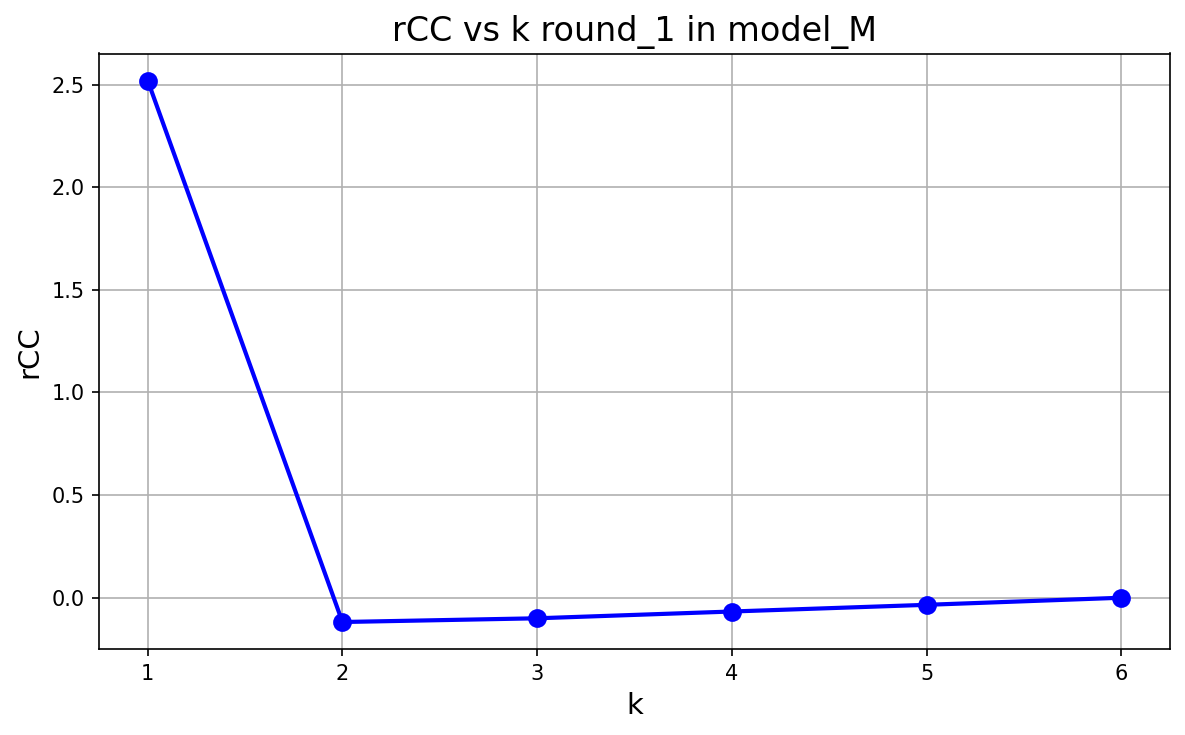

Optimal number of parameters to estimate for M: 2


In [9]:
from middoe.sc_estima import estima
round = 1
ranking, k_optimal_value, rCC_values, J_k_values, best_uncert_result = estima(resultun, system, models, iden_opt, round)

[INFO] Reading from data.xlsx


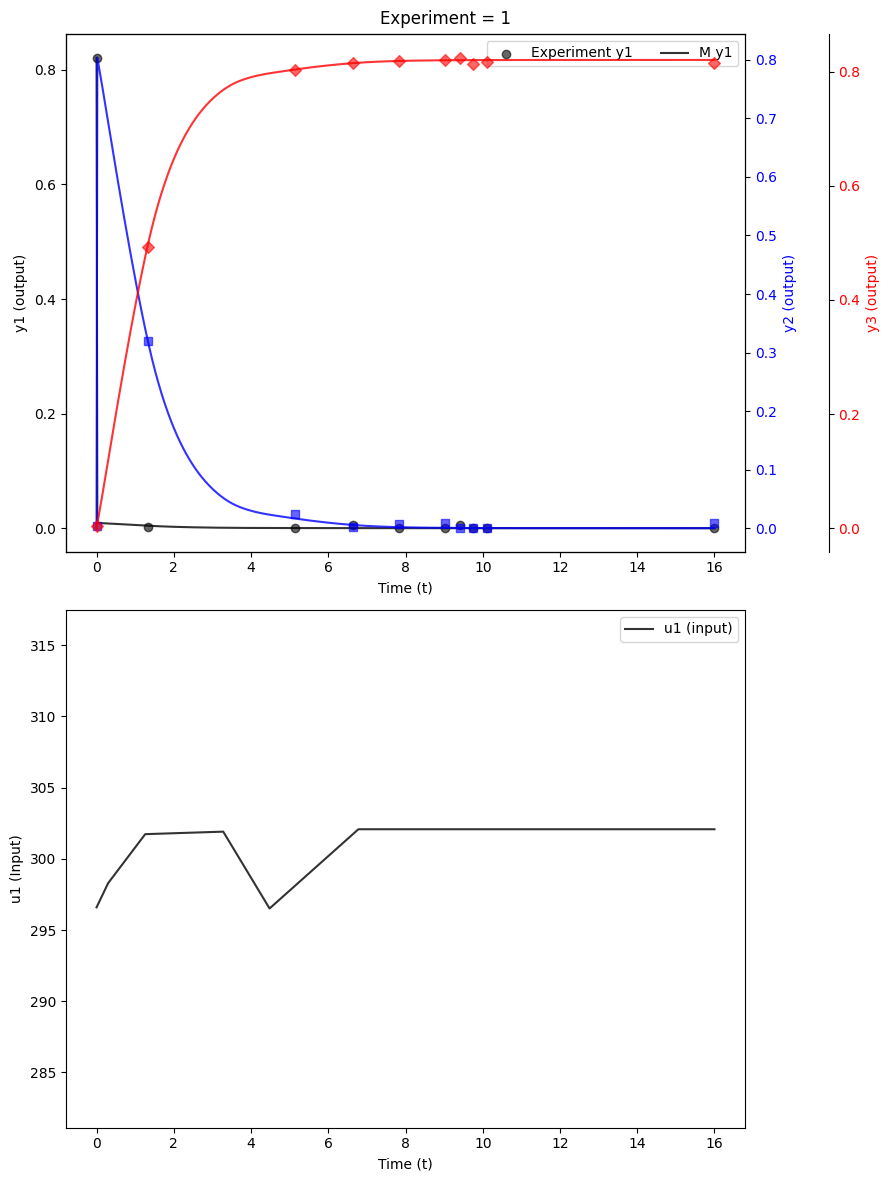

reference t value for model M and round 1: 2.0638985616280205
estimated t values for model M and round 1: [65.84583472  1.03282866]
P-value for model M and round 1: 100.0



{'M': np.float64(2.0638985616280205)}

In [10]:
from middoe.log_utils import  save_rounds
round_data={}
save_rounds(round, resultun,  'MBDOE-D1', round_data, models, iden_opt, obs, system, ranking= ranking, k_optimal_value= k_optimal_value, rCC_values= rCC_values, J_k_values= J_k_values,  best_uncert_result= best_uncert_result)

In [11]:
from middoe.des_pp import mbdoe_pp
round = 2
designs = mbdoe_pp(des_opt, system, models, round=round, num_parallel_runs=16)

In [12]:
from middoe.krnl_expera import expera
expera(system, models, insilicos, designs, expr=round, swps=designs['swps'])

[✓] In-silico data saved to: C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\data.xlsx
[INFO] Model used         : M
[INFO] Design case        : MBDoE
[INFO] Responses simulated:
   - y1         | measurable      | std.dev = 0.005
   - y2         | measurable      | std.dev = 0.005
   - y3         | measurable      | std.dev = 0.005


(WindowsPath('C:/Users/Tadmin/PycharmProjects/middoe/tests/paper3/2D+2D-LC/data.xlsx'),
      MES_X:y1  MES_Y:y1  MES_E:y1  MES_X:y2  MES_Y:y2  MES_E:y2  MES_X:y3  \
 0        0.00  0.342892     0.005      0.00  0.000549     0.005      0.00   
 1        1.14  0.007413     0.005      1.14  0.161934     0.005      1.14   
 2        1.46  0.003187     0.005      1.46  0.123109     0.005      1.46   
 3        1.78  0.000000     0.005      1.78  0.095210     0.005      1.78   
 4        3.04  0.007238     0.005      3.04  0.040234     0.005      3.04   
 ..        ...       ...       ...       ...       ...       ...       ...   
 796       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 797       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 798       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 799       NaN       NaN       NaN       NaN       NaN       NaN       NaN   
 800       NaN       NaN       NaN       NaN       NaN

In [13]:
models['mutation']['M'] = [True, True, True, True, True, True]


In [14]:

from middoe.iden_parmest import parmest
resultpr = parmest(system, models, iden_opt, case='strov')

[INFO] Reading from data.xlsx


In [15]:
from middoe.iden_uncert import uncert
uncert_results = uncert(resultpr, system, models, iden_opt)
resultun = uncert_results['results']
obs = uncert_results['obs']

[INFO] Reading from data.xlsx
active_idx: [0 1 2 3 4 5]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/6, cond(Q)≈inf, cond(M)≈inf, λ_min(M)≈0.00e+00; ILL-CONDITIONED
INFO:middoe.iden_uncert:Solver M: Estimated θ = [6.78778109e+05 4.84182276e+04 4.60399497e-01 9.02579122e+04
 3.02537879e+03 5.89517878e+04]
INFO:middoe.iden_uncert:Solver M: t-val = [           inf            inf   108.87676537 67439.97889355
   108.88704382 41740.72645008]


CI: [0.00000000e+00 0.00000000e+00 8.47789160e-03 2.68321879e+00
 5.57046923e+01 2.83155633e+00]


[INFO] Reading from data.xlsx
Estimability analysis for round 2 is running
Parameter ranking from most estimable to least estimable for M in round 2: [2, 4, 3, 5, 0, 1]
J_theta (baseline): 36.13456551950248
[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx
active_idx: [2]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=1/1, cond(Q)≈1.00e+00, cond(M)≈1.00e+00, λ_min(M)≈1.81e+05; OK


CI: [0.00470476]
J_k (1 parameters): 218.5382109785432
rCC (1 parameters): 2.8733940909840117
[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx
active_idx: [2 4]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=2/2, cond(Q)≈1.80e+05, cond(M)≈3.26e+10, λ_min(M)≈1.96e-06; ILL-CONDITIONED


CI: [8.93290189e-03 1.43118828e+03]
J_k (2 parameters): 35.71966164530112
rCC (2 parameters): -0.06897168819000754
[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx
active_idx: [2 3 4]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=3/3, cond(Q)≈1.28e+06, cond(M)≈1.65e+12, λ_min(M)≈3.44e-08; ILL-CONDITIONED


... (3 outputs left out)

INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=4/5, cond(Q)≈inf, cond(M)≈inf, λ_min(M)≈0.00e+00; ILL-CONDITIONED


CI: [0.00000000e+00 9.64970199e-02 4.59441273e+04 1.01384389e+03
 1.25725721e+04]
J_k (5 parameters): 35.896797875871
rCC (5 parameters): -0.019308529373683096
[INFO] Reading from data.xlsx
[INFO] Reading from data.xlsx
active_idx: [2 4]


INFO:middoe.iden_uncert:Conditioning diagnostics: Rank(Q)=2/2, cond(Q)≈6.48e+03, cond(M)≈4.20e+07, λ_min(M)≈1.74e-03; OK


CI: [7.94745915e-03 4.79714354e+01]


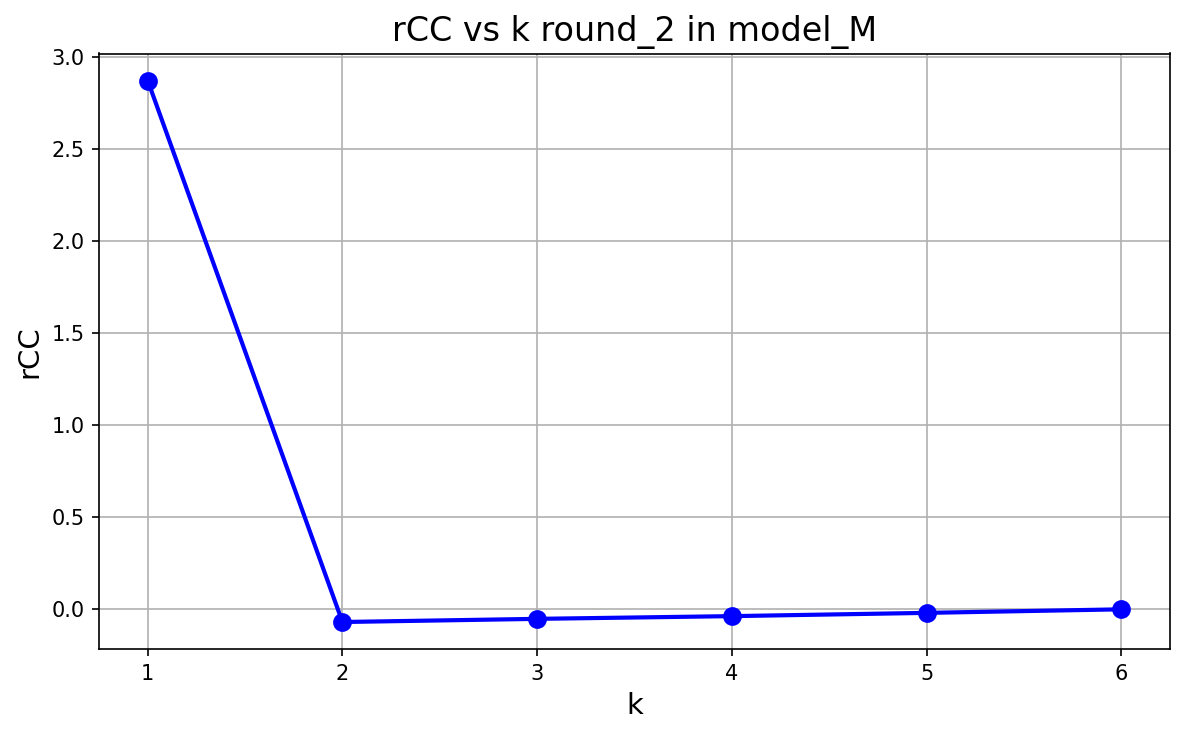

Optimal number of parameters to estimate for M: 2


In [16]:
from middoe.sc_estima import estima
ranking, k_optimal_value, rCC_values, J_k_values, best_uncert_result = estima(resultun, system, models, iden_opt, round)

[INFO] Reading from data.xlsx


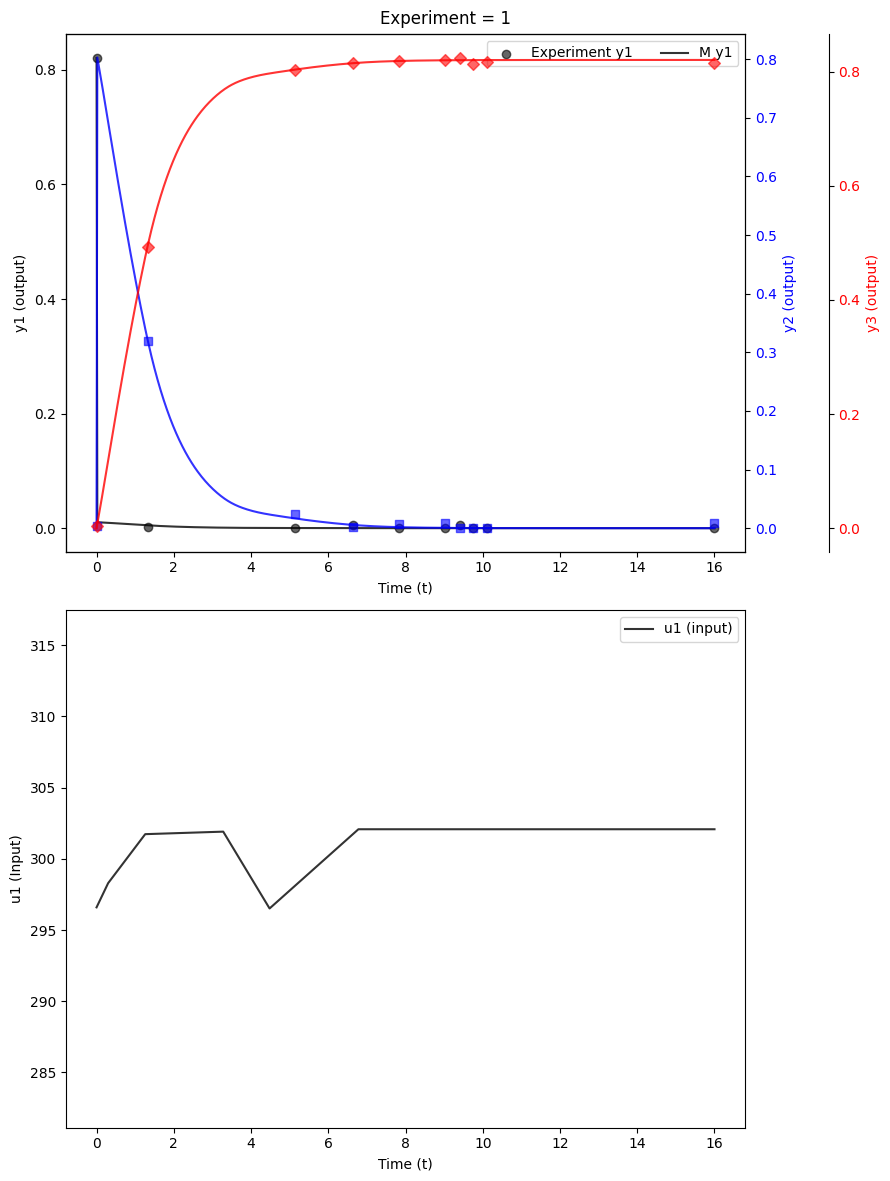

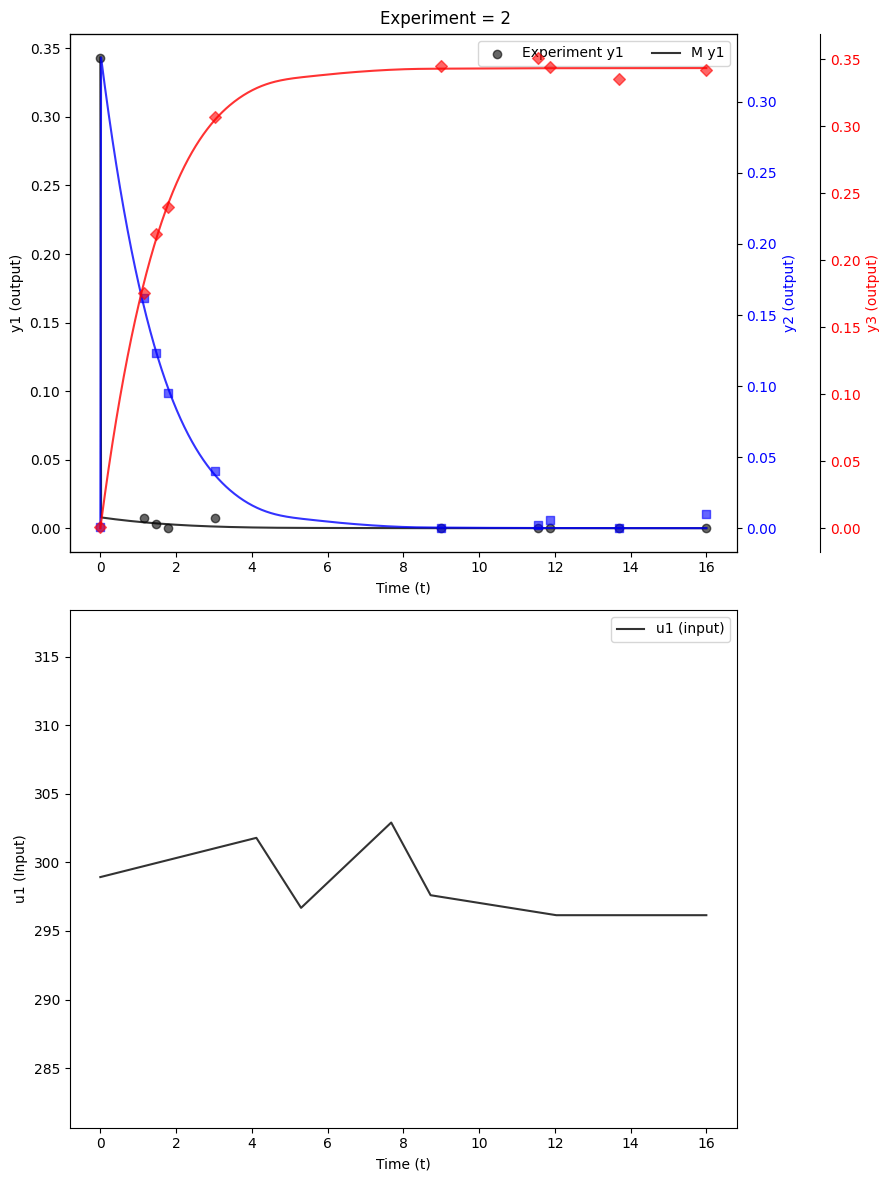

reference t value for model M and round 2: 2.0048792881880564
estimated t values for model M and round 2: [111.01034156  65.25618988]
P-value for model M and round 2: 100.0



{'M': np.float64(2.0048792881880564)}

In [17]:
from middoe.log_utils import  save_rounds
save_rounds(round, resultun,  'MBDOE-D2', round_data, models, iden_opt, obs, system, ranking= ranking, k_optimal_value= k_optimal_value, rCC_values= rCC_values, J_k_values= J_k_values,  best_uncert_result= best_uncert_result)

In [18]:
from middoe.log_utils import save_to_jac
save_to_jac(round_data, purpose="iden")

[INFO] Results saved to: C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\iden_results.jac


In [1]:
from middoe.log_utils import load_from_jac
results = load_from_jac()
iden = results['iden']

Loaded: iden_results.jac
File not found: sensa_results.jac


INFO:middoe.iden_utils:Starting pcomp_plot.


Loaded: iden_results.jac
File not found: sensa_results.jac


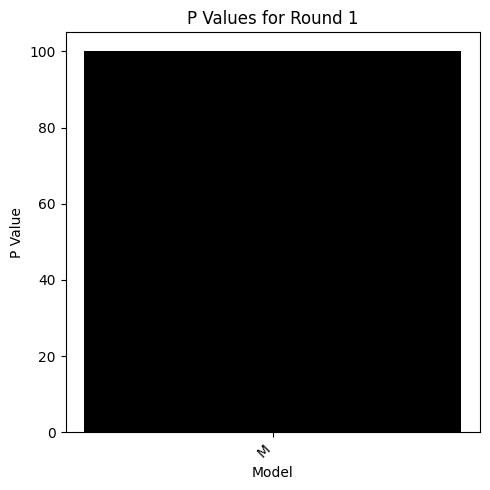

INFO:middoe.iden_utils:P values plot for Round 1 saved to C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\post_processing\p_values_round_1.png.


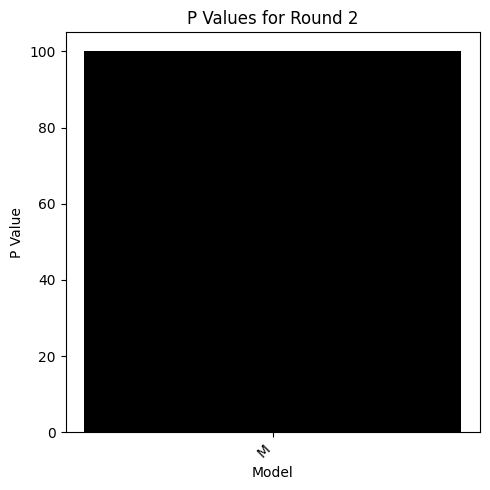

INFO:middoe.iden_utils:P values plot for Round 2 saved to C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\post_processing\p_values_round_2.png.
INFO:middoe.iden_utils:Starting tcomp_plot.


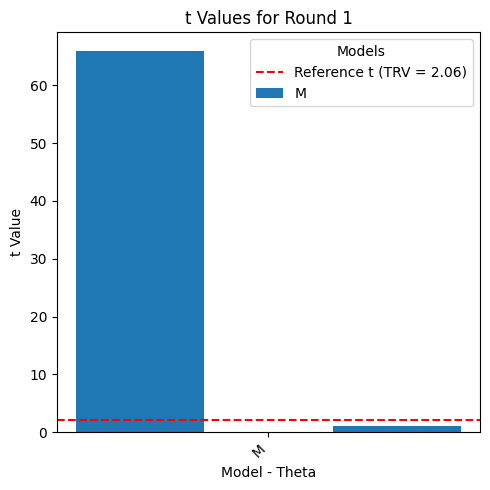

INFO:middoe.iden_utils:T values plot for Round 1 saved to C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\post_processing\t_values_round_1.png.


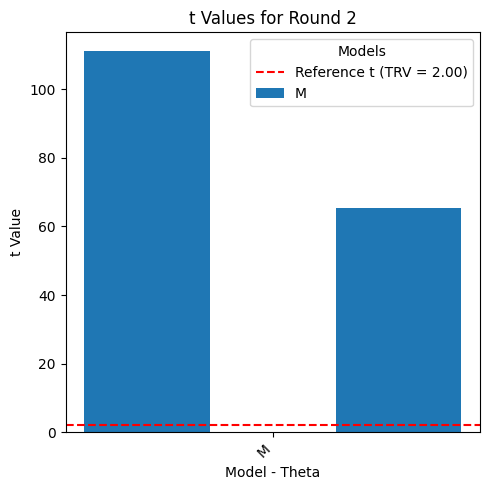

INFO:middoe.iden_utils:T values plot for Round 2 saved to C:\Users\Tadmin\PycharmProjects\middoe\tests\paper3\2D+2D-LC\post_processing\t_values_round_2.png.


Post-processing model: M


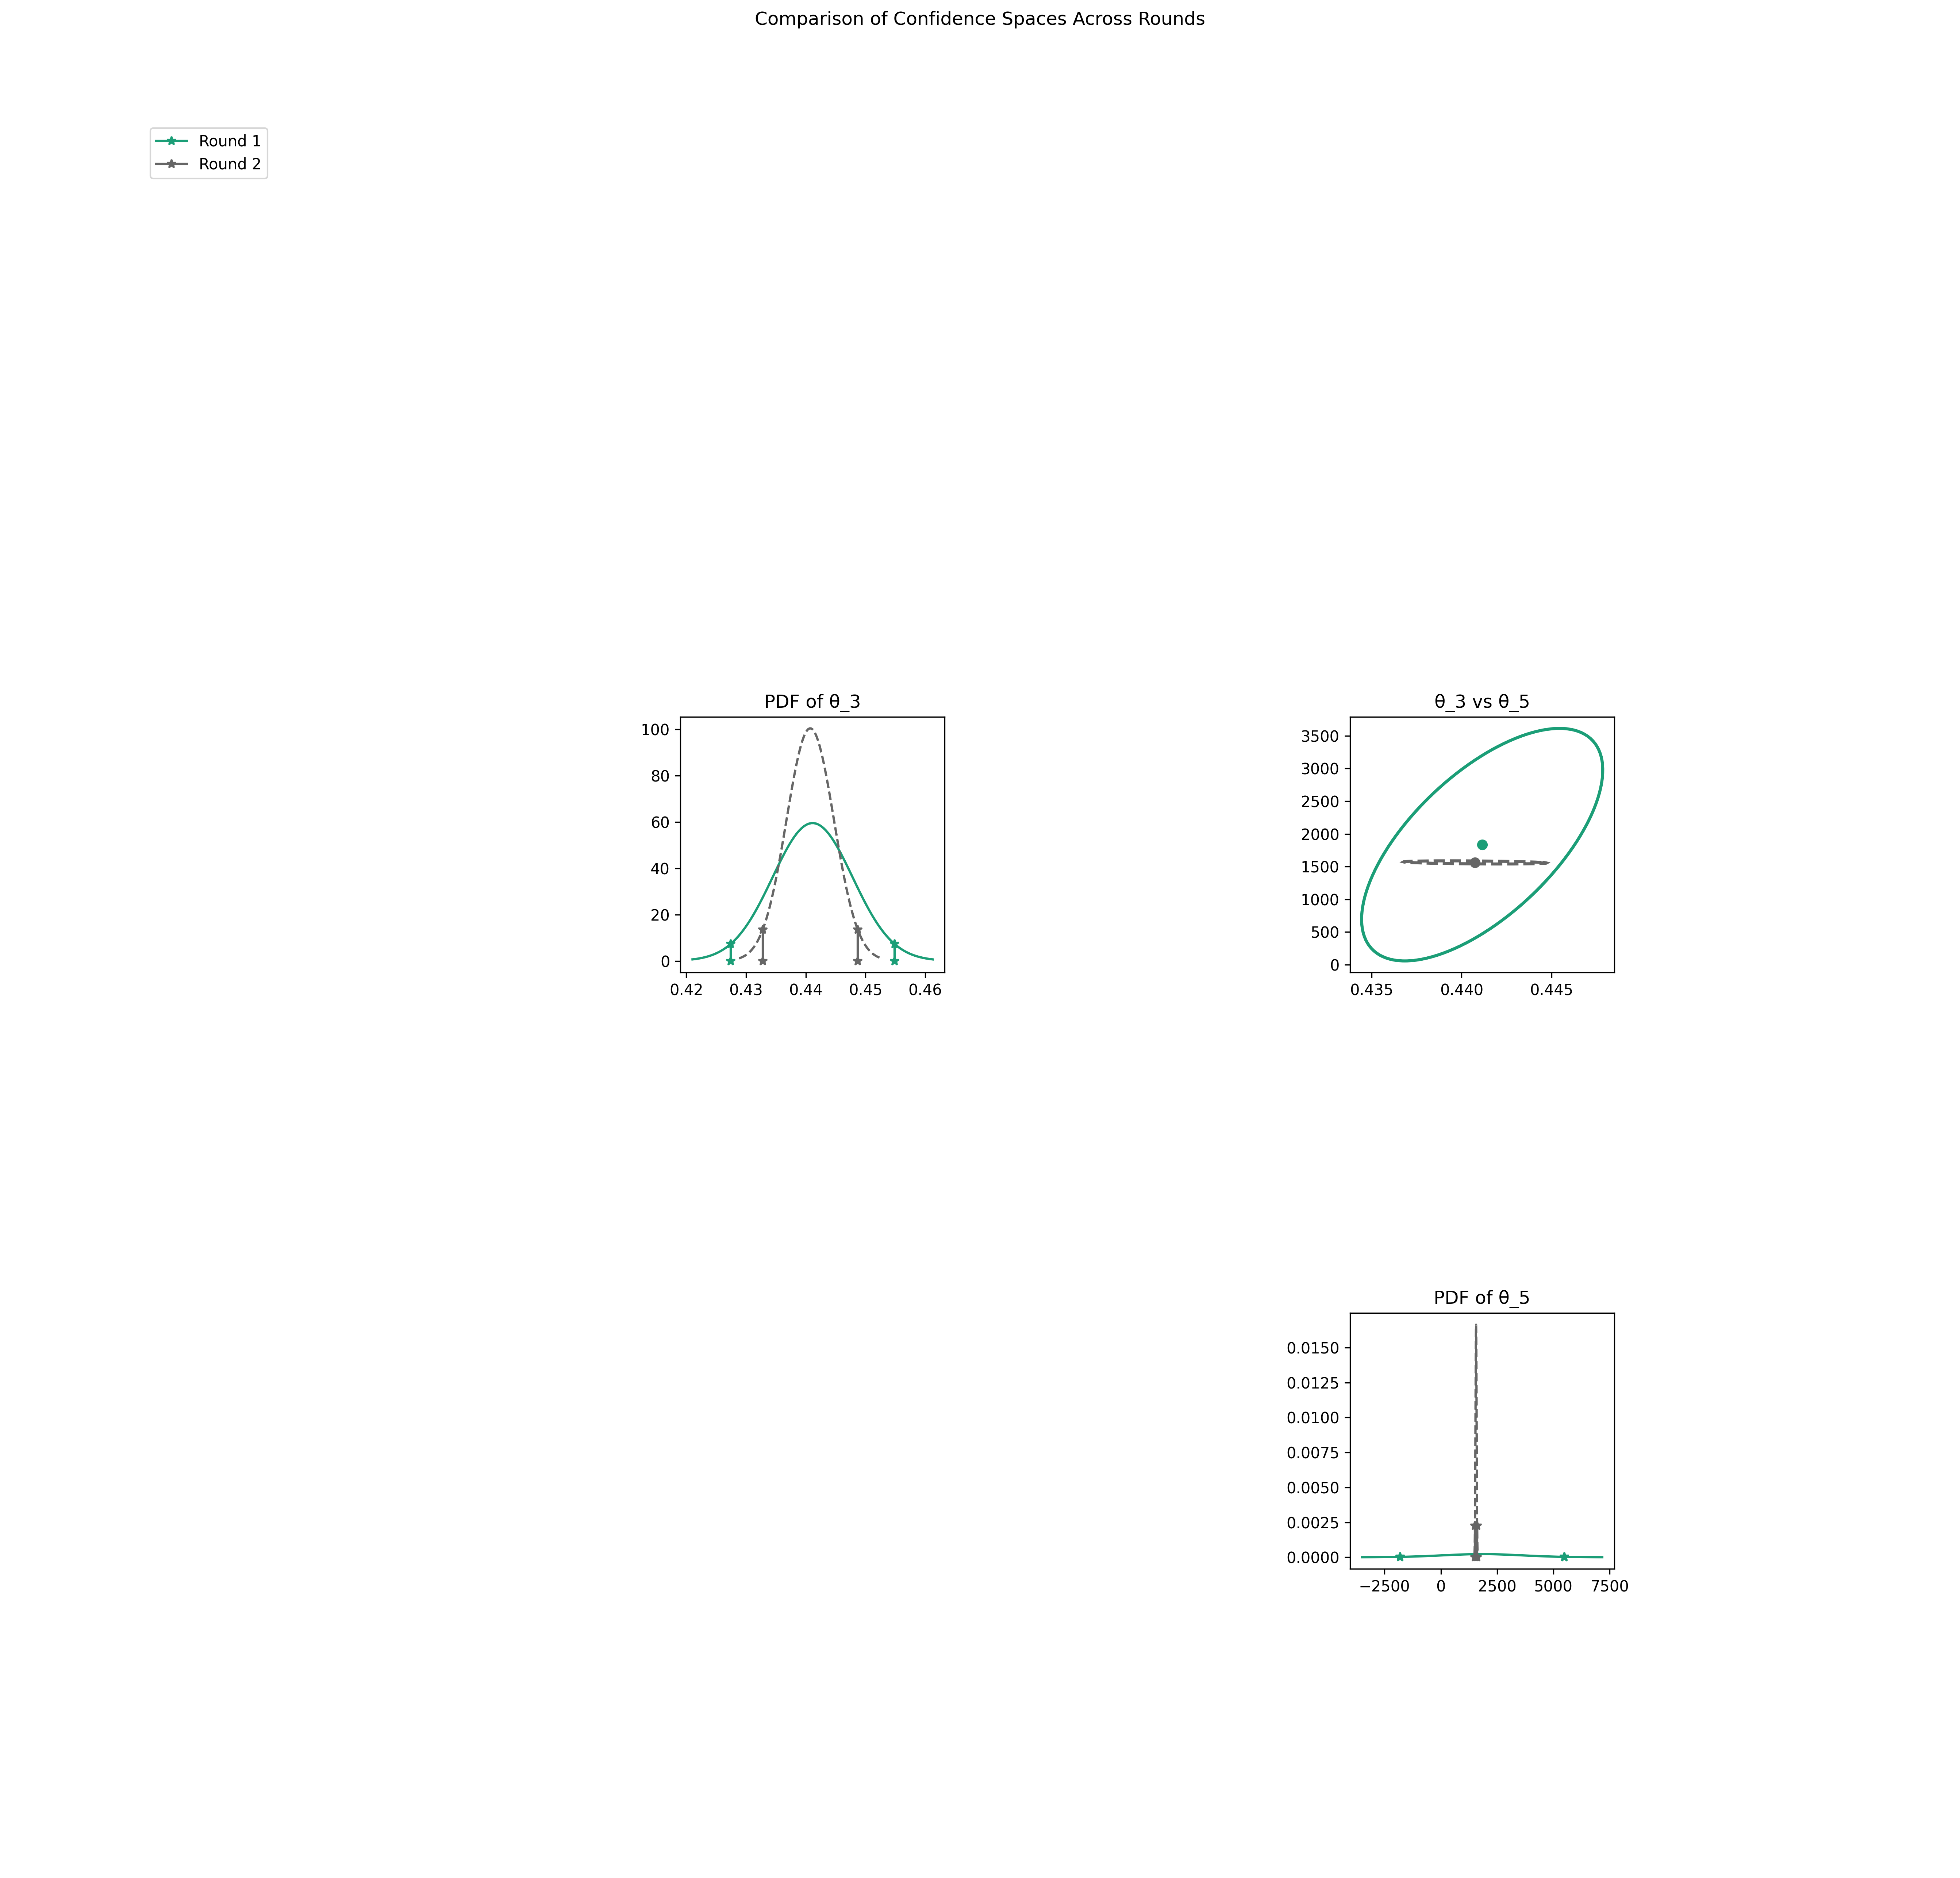

IndexError: index 0 is out of bounds for axis 0 with size 0

In [20]:
from middoe.log_utils import load_from_jac
results = load_from_jac()
iden = results['iden']

from middoe.iden_utils import run_postprocessing
run_postprocessing(
    round_data=results['iden'],
    solvers=['M'],
    selected_rounds=[ 1, 2],
    plot_global_p_and_t=True,
    plot_confidence_spaces=True,
    plot_p_and_t_tests=True,
    export_excel_reports=True,
    plot_estimability=True
)